# miRNA–target prediction with a CNN (Hejret 2023 AGO2 CLASH)

Predicts whether a miRNA binds a 50-nt target site, using only the `noncodingRNA` and `gene` sequences.

**Run:** put `AGO2_CLASH_Hejret2023_train.tsv.gz` (and later `..._test.tsv.gz`) from
[Zenodo](https://zenodo.org/records/20540907) next to this notebook, then *Run All*.
`pip install torch pandas numpy scikit-learn matplotlib`

Steps: 1 data & split → 2 encoding → 3 model → 4 training → 5 validation evaluation (CNN vs baseline) → 6 final test (run once).

Evaluation is done by the separate, model-agnostic `evaluate.py`, so any model's predictions can be scored the same way.

In [1]:
import copy
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, precision_recall_curve,
                             roc_auc_score, roc_curve)

SEED = 42
BLUE, ORANGE = "#2a78d6", "#eb6834"  # CNN / train = blue, baseline / val = orange
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 110})

## 1. Data and 80/20 split

Only the three allowed columns are loaded, so leaky columns such as `Nunique` can't be used by accident.
The split is stratified (same positive/negative ratio in both parts) and seeded, so it is reproducible.

In [2]:
df = pd.read_csv("AGO2_CLASH_Hejret2023_train.tsv.gz", sep="\t", usecols=["noncodingRNA", "gene", "label"])
print(df["label"].value_counts())
print("target lengths:", df["gene"].str.len().unique())
print("letters:", set("".join(df["noncodingRNA"] + df["gene"])))

train_df, val_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
val_df.to_csv("val_split.tsv", sep="\t", index=False)  # reference file for evaluate.py
print(len(train_df), "train /", len(val_df), "val")

label
1    4084
0    4056
Name: count, dtype: int64
target lengths: [50]
letters: {'A', 'T', 'G', 'C'}
6512 train / 1628 val


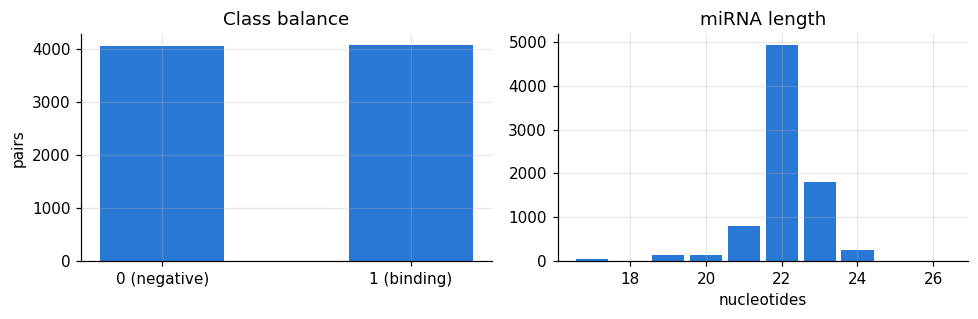

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
counts = df["label"].value_counts().sort_index()
ax[0].bar(["0 (negative)", "1 (binding)"], counts.values, color=BLUE, width=0.5)
ax[0].set_title("Class balance")
ax[0].set_ylabel("pairs")
lens = df["noncodingRNA"].str.len()
ax[1].hist(lens, bins=np.arange(lens.min(), lens.max() + 2) - 0.5, color=BLUE, rwidth=0.85)
ax[1].set_title("miRNA length")
ax[1].set_xlabel("nucleotides")
plt.tight_layout()
plt.show()

## 2. Encoding: 2D pairing matrix

Each pair becomes a 50 × 26 grid (target positions × miRNA positions):
**1** = Watson–Crick pair (A–T, C–G), **0.5** = G–T wobble, **0** = no pair or padding.
miRNAs are padded on the 3' end so the seed (positions 2–8) stays in the same columns.
Consecutive base pairing appears as a diagonal run, which is what the CNN looks for.

In [4]:
MIRNA_LEN = 26  # longest miRNA in the training data
IDX = {c: i for i, c in enumerate("ACGT")}  # anything else (padding "N") -> 4
PAIR = np.zeros((5, 5), dtype=np.float32)    # PAIR[target_base, mirna_base]
for a, b, v in [("A","T",1), ("T","A",1), ("C","G",1), ("G","C",1), ("G","T",.5), ("T","G",.5)]:
    PAIR[IDX[a], IDX[b]] = v

def encode(df):
    t = np.array([[IDX.get(c, 4) for c in s] for s in df["gene"]])
    # shortcut: miRNAs longer than MIRNA_LEN lose their 3' end; raise MIRNA_LEN if a dataset has longer ones
    m = np.array([[IDX.get(c, 4) for c in s[:MIRNA_LEN].ljust(MIRNA_LEN, "N")] for s in df["noncodingRNA"]])
    return PAIR[t[:, :, None], m[:, None, :]][:, None]  # (n, 1, 50, 26)

chk = encode(pd.DataFrame({"gene": ["AG" + "C" * 48], "noncodingRNA": ["T" * 20]}))
assert chk.shape == (1, 1, 50, 26) and chk[0, 0, 0, 0] == 1 and chk[0, 0, 1, 0] == .5 and chk[0, 0, 0, 25] == 0

X_train, y_train = encode(train_df), train_df["label"].values
X_val, y_val = encode(val_df), val_df["label"].values
print(X_train.shape, X_val.shape)

(6512, 1, 50, 26) (1628, 1, 50, 26)


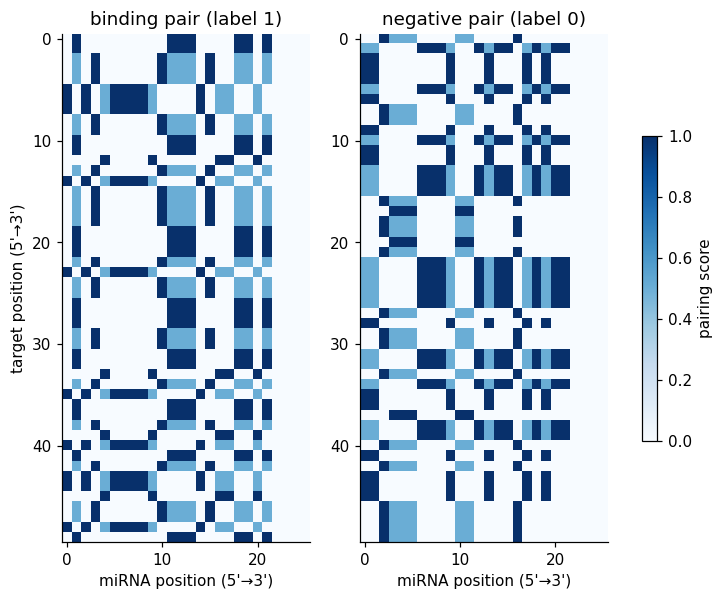

In [5]:
# one binding and one negative example from the training set
fig, ax = plt.subplots(1, 2, figsize=(8, 6))
for a, lab, name in [(ax[0], 1, "binding pair (label 1)"), (ax[1], 0, "negative pair (label 0)")]:
    i = np.flatnonzero(y_train == lab)[0]
    im = a.imshow(X_train[i, 0], cmap="Blues", vmin=0, vmax=1, aspect="auto")
    a.set_title(name)
    a.set_xlabel("miRNA position (5'→3')")
    a.grid(False)
ax[0].set_ylabel("target position (5'→3')")
fig.colorbar(im, ax=ax, shrink=0.6, label="pairing score")
plt.show()

## 3. Model

Three 3×3 conv layers find diagonal pairing patterns; a 2×2 max pool widens their view to about seed length (~10 nt).
Global max pooling keeps each filter's best match anywhere in the grid (the "slide the miRNA and keep the best match" idea).
The model is small (~56k parameters) because there are only ~6.5k training pairs.
The output is a logit; the sigmoid is applied in the loss during training and explicitly at prediction time.

In [6]:
torch.manual_seed(SEED)
model = nn.Sequential(
    nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(),
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
    nn.AdaptiveMaxPool2d(1), nn.Flatten(),
    nn.Dropout(0.3),
    nn.Linear(64, 1),
)
assert model(torch.zeros(4, 1, 50, 26)).shape == (4, 1)
print(sum(p.numel() for p in model.parameters()), "parameters")

55809 parameters


## 4. Training with early stopping

Adam (lr 1e-3), batch size 64, binary cross-entropy. After each epoch the validation loss is checked;
the best weights are kept and training stops after 5 epochs without improvement.

In [7]:
dev = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(dev)
train_dl = DataLoader(TensorDataset(torch.tensor(X_train), torch.tensor(y_train, dtype=torch.float32)),
                      batch_size=64, shuffle=True)
Xv, yv = torch.tensor(X_val).to(dev), torch.tensor(y_val, dtype=torch.float32).to(dev)

opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.BCEWithLogitsLoss()
best, wait, patience = float("inf"), 0, 5
hist = {"train": [], "val": [], "acc": []}

for epoch in range(50):
    model.train()
    total = 0
    for xb, yb in train_dl:
        xb, yb = xb.to(dev), yb.to(dev)
        opt.zero_grad()
        loss = loss_fn(model(xb).squeeze(1), yb)
        loss.backward()
        opt.step()
        total += loss.item() * len(xb)

    model.eval()
    with torch.no_grad():
        logits = model(Xv).squeeze(1)
        val_loss = loss_fn(logits, yv).item()
        val_acc = ((logits > 0).float() == yv).float().mean().item()
    hist["train"].append(total / len(X_train)); hist["val"].append(val_loss); hist["acc"].append(val_acc)
    print(f"epoch {epoch:2d}  train {hist['train'][-1]:.3f}  val {val_loss:.3f}  acc {val_acc:.3f}")

    if val_loss < best:
        best, best_state, best_epoch, wait = val_loss, copy.deepcopy(model.state_dict()), epoch, 0
    else:
        wait += 1
        if wait == patience:
            break

model.load_state_dict(best_state)
torch.save(best_state, "cnn.pt")
print(f"kept epoch {best_epoch} (val loss {best:.3f}), saved cnn.pt")

epoch  0  train 0.692  val 0.681  acc 0.584
epoch  1  train 0.656  val 0.636  acc 0.598
epoch  2  train 0.573  val 0.557  acc 0.701
epoch  3  train 0.526  val 0.511  acc 0.750
epoch  4  train 0.507  val 0.502  acc 0.753
epoch  5  train 0.501  val 0.492  acc 0.762
epoch  6  train 0.487  val 0.491  acc 0.763
epoch  7  train 0.484  val 0.497  acc 0.763
epoch  8  train 0.478  val 0.487  acc 0.765
epoch  9  train 0.467  val 0.544  acc 0.726
epoch 10  train 0.456  val 0.485  acc 0.761
epoch 11  train 0.448  val 0.480  acc 0.775
epoch 12  train 0.448  val 0.498  acc 0.760
epoch 13  train 0.447  val 0.484  acc 0.771
epoch 14  train 0.431  val 0.490  acc 0.763
epoch 15  train 0.432  val 0.513  acc 0.757
epoch 16  train 0.416  val 0.505  acc 0.769
kept epoch 11 (val loss 0.480), saved cnn.pt


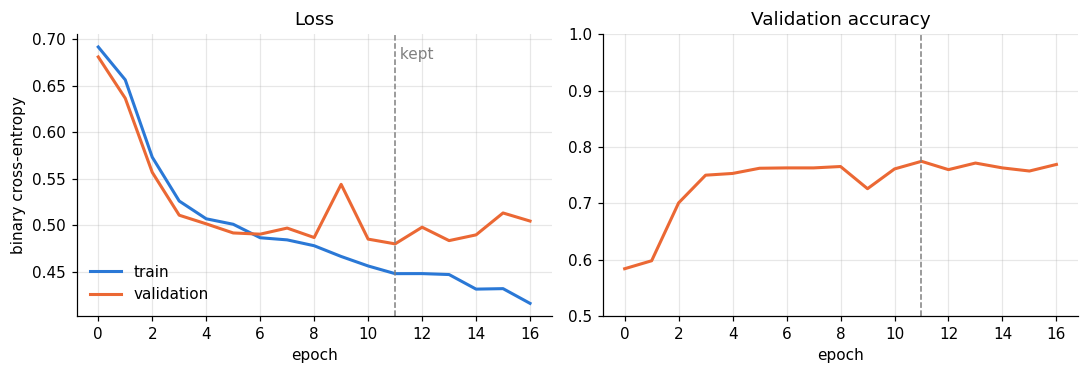

In [8]:
ep = range(len(hist["train"]))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(ep, hist["train"], color=BLUE, lw=2, label="train")
ax[0].plot(ep, hist["val"], color=ORANGE, lw=2, label="validation")
ax[0].axvline(best_epoch, color="gray", ls="--", lw=1)
ax[0].text(best_epoch, max(hist["train"]), " kept", color="gray", va="top")
ax[0].set(title="Loss", xlabel="epoch", ylabel="binary cross-entropy")
ax[0].legend(frameon=False)
ax[1].plot(ep, hist["acc"], color=ORANGE, lw=2)
ax[1].axvline(best_epoch, color="gray", ls="--", lw=1)
ax[1].set(title="Validation accuracy", xlabel="epoch", ylim=(0.5, 1))
plt.tight_layout()
plt.show()

## 5. Validation: CNN vs a rule-based baseline

**Baseline:** score = longest run of paired bases along any binding diagonal (i.e. slide the miRNA along
the target and keep the best unbroken match). If the CNN doesn't beat this, it hasn't learned much.

Both models write a predictions file (`gene`, `noncodingRNA`, `score`), which `evaluate.py` scores.
Main metric: **AUROC** (threshold-free; 0.5 = random). Also AUPRC, and accuracy / F1 / MCC at a threshold.

In [9]:
def predict_cnn(df):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.tensor(encode(df)).to(dev)).squeeze(1)).cpu().numpy()

def longest_run(g):
    g = np.fliplr(g) > 0  # flip so binding anti-diagonals become normal diagonals
    best = 0
    for k in range(-g.shape[0] + 1, g.shape[1]):
        run = 0
        for v in np.diagonal(g, k):
            run = run + 1 if v else 0
            best = max(best, run)
    return best

def predict_baseline(df):
    return np.array([longest_run(g[0]) for g in encode(df)])

cols = ["gene", "noncodingRNA"]
val_df[cols].assign(score=predict_cnn(val_df)).to_csv("pred_cnn_val.tsv", sep="\t", index=False)
val_df[cols].assign(score=predict_baseline(val_df)).to_csv("pred_baseline_val.tsv", sep="\t", index=False)

In [10]:
!{sys.executable} evaluate.py val_split.tsv pred_cnn_val.tsv
!{sys.executable} evaluate.py val_split.tsv pred_baseline_val.tsv 7

AUROC     0.845
AUPRC     0.865
Accuracy  0.775   (threshold 0.5)
F1        0.760
MCC       0.554
Confusion [[TN FP] [FN TP]]:
 [[679 132]
 [235 582]]
AUROC     0.761
AUPRC     0.737
Accuracy  0.694   (threshold 7.0)
F1        0.726
MCC       0.398
Confusion [[TN FP] [FN TP]]:
 [[471 340]
 [158 659]]


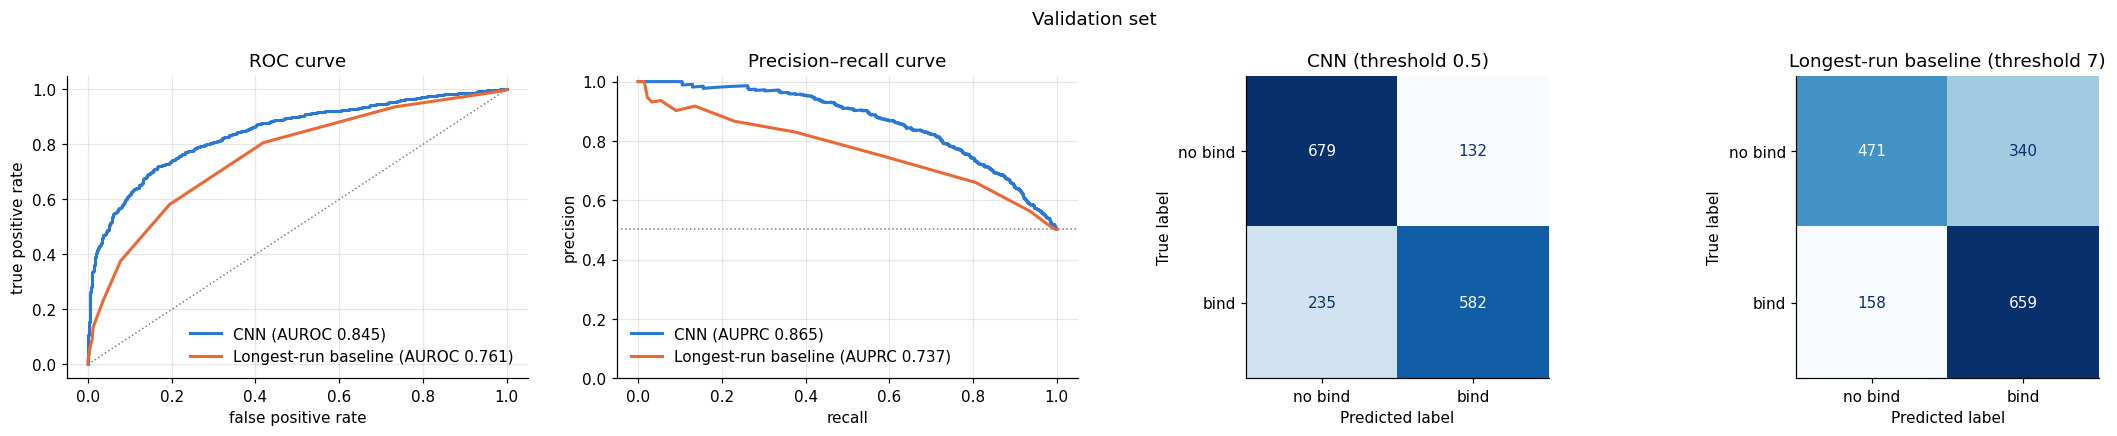

In [11]:
def plot_eval(ref_path, runs, title):
    """runs: list of (name, predictions file, threshold, color). Display only; numbers come from evaluate.py."""
    y = pd.read_csv(ref_path, sep="\t")["label"]
    preds = [(n, pd.read_csv(p, sep="\t")["score"], t, c) for n, p, t, c in runs]
    fig, ax = plt.subplots(1, 2 + len(runs), figsize=(5 * (2 + len(runs)), 4))
    for n, s, t, c in preds:
        fpr, tpr, _ = roc_curve(y, s)
        prec, rec, _ = precision_recall_curve(y, s)
        ax[0].plot(fpr, tpr, color=c, lw=2, label=f"{n} (AUROC {roc_auc_score(y, s):.3f})")
        ax[1].plot(rec, prec, color=c, lw=2, label=f"{n} (AUPRC {average_precision_score(y, s):.3f})")
    ax[0].plot([0, 1], [0, 1], color="gray", ls=":", lw=1)
    ax[0].set(title="ROC curve", xlabel="false positive rate", ylabel="true positive rate")
    ax[1].axhline(y.mean(), color="gray", ls=":", lw=1)
    ax[1].set(title="Precision–recall curve", xlabel="recall", ylabel="precision", ylim=(0, 1.02))
    for a in ax[:2]:
        a.legend(frameon=False, loc="lower right" if a is ax[0] else "lower left")
    for a, (n, s, t, c) in zip(ax[2:], preds):
        ConfusionMatrixDisplay.from_predictions(y, (s >= t).astype(int), display_labels=["no bind", "bind"],
                                                cmap="Blues", colorbar=False, ax=a)
        a.set_title(f"{n} (threshold {t:g})")
        a.grid(False)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_eval("val_split.tsv", [("CNN", "pred_cnn_val.tsv", 0.5, BLUE),
                            ("Longest-run baseline", "pred_baseline_val.tsv", 7, ORANGE)], "Validation set")

## 6. Final test — run once, after all model choices are fixed

Set `RUN_TEST = True` only when nothing (architecture, encoding, threshold) will change any more.
Changing the model after looking at test results makes the test score optimistic.

AUROC     0.869
AUPRC     0.874
Accuracy  0.793   (threshold 0.5)
F1        0.781
MCC       0.585
Confusion [[TN FP] [FN TP]]:
 [[430  93]
 [118 377]]
AUROC     0.759
AUPRC     0.717
Accuracy  0.681   (threshold 7.0)
F1        0.715
MCC       0.383
Confusion [[TN FP] [FN TP]]:
 [[286 237]
 [ 88 407]]


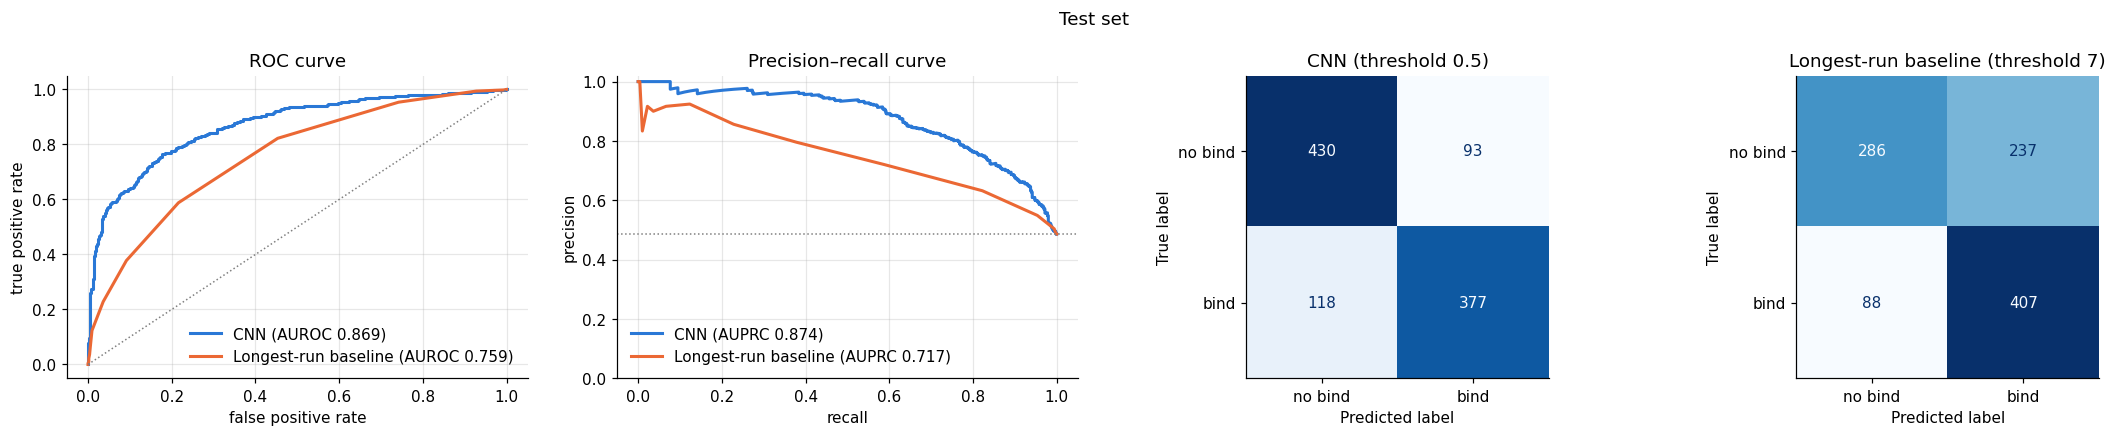

In [ ]:
RUN_TEST = False

if RUN_TEST:
    test_df = pd.read_csv("AGO2_CLASH_Hejret2023_test.tsv.gz", sep="\t", usecols=["noncodingRNA", "gene", "label"])
    test_df.to_csv("test_ref.tsv", sep="\t", index=False)
    test_df[cols].assign(score=predict_cnn(test_df)).to_csv("pred_cnn_test.tsv", sep="\t", index=False)
    test_df[cols].assign(score=predict_baseline(test_df)).to_csv("pred_baseline_test.tsv", sep="\t", index=False)
    !{sys.executable} evaluate.py test_ref.tsv pred_cnn_test.tsv
    !{sys.executable} evaluate.py test_ref.tsv pred_baseline_test.tsv 7
    plot_eval("test_ref.tsv", [("CNN", "pred_cnn_test.tsv", 0.5, BLUE),
                               ("Longest-run baseline", "pred_baseline_test.tsv", 7, ORANGE)], "Test set")